In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv
from itertools import cycle

from halcyon.results.manipulate_results_df import (df_with_ground_truth_as_kind_of_model)
from halcyon.results.plot_from_df import plot_model_plots
from halcyon.Simulators import SimulationResult
from halcyon.ModelRunner.ModelRunner import ModelRunner
from halcyon.results import DfColumnNames
from halcyon.Models import MLP
from halcyon.Models.Losses import MSELossPlusL1

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


True

**Note**: create a `.env` for for the CropXR MLFlow as shown in [the readme](../README.md#mlflow-integration) of this repo.

# Toy example for 20 genes and MLP that models them

## Loading Simulation data

In [14]:
sim_run_id = 'd660c1d337c34d98a349605d9b4d5b47'

run = mlflow.get_run(sim_run_id)

params = run.data.params
print(params)

# Load data
ml_flow_download_path = mlflow.artifacts.download_artifacts(
    run_id=sim_run_id, artifact_path="dataset"
)
sim_output = SimulationResult.load_from_pkl(
    Path(ml_flow_download_path) / "simulation_result.pkl"
)

# From raw sim output to datasets
single_ko_dataset, double_ko_dataset, time_scaling_factor = (
    sim_output.create_datasets()
)

{'nr_genes': '20', 'sparsity': '0.1', 'num_modules': '2', 'noise_level': 'MEDIUM', 'seed': '174'}


## Setting up model runner

In [ ]:
# Feel free to change to CPU if you want to

device = cycle(["cuda:0", "cuda:1"])
optimizer_kwargs = {"lr": 0.01}
batch_size = 32

loss = MSELossPlusL1(0.0)
ml_model = MLP(
    modelled_gene_labels=single_ko_dataset.genes,
    hidden_size=10,
    nr_layers=2,
    condition_names=single_ko_dataset.all_environments,
    synthesis_only_positive=False,
    device=next(device),
)

model_runner = ModelRunner(
    model=ml_model,
    batch_size=batch_size,
    optimizer_kwargs=optimizer_kwargs,
    loss=loss,
)

## Loading model

In [23]:
model_run_id = '6a3375f5c070446f996b2719f487da25'

# Load data
ml_flow_download_path = mlflow.artifacts.download_artifacts(
    artifact_uri='mlflow-artifacts:/4/6a3375f5c070446f996b2719f487da25/artifacts/model/trainer_MLP_hidden_size_10_synthesis_only_positive_False_nr_layers_2_lr_0.01_patience_50_min_delta_1e-05_batch_size_32_loss_fn_MSELossPlusL1 with lambda=0.0_lambda_l1_0.0_model_class_MLP_epoch1030.pt')

'/tmp/tmpxvc79pwq/trainer_MLP_hidden_size_10_synthesis_only_positive_False_nr_layers_2_lr_0.01_patience_50_min_delta_1e-05_batch_size_32_loss_fn_MSELossPlusL1 with lambda=0.0_lambda_l1_0.0_model_class_MLP_epoch1030.pt'

In [25]:
model_runner.load(Path(ml_flow_download_path))

## Running model

In [26]:
# E.g. on single knockouts
condition_string, ground_truth, prediction = model_runner.predict(single_ko_dataset)

100%|██████████| 1/1 [00:04<00:00,  4.76s/it]


(['KO: Node_3. Env: None',
  'KO: Node_15. Env: None',
  'KO: Node_7. Env: None',
  'KO: Node_2. Env: None',
  'KO: Node_12. Env: None',
  'KO: Node_8. Env: None',
  'KO: Node_5. Env: None',
  'KO: Node_16. Env: None',
  'KO: Node_1. Env: None',
  'KO: Node_19. Env: None',
  'KO: Node_14. Env: None',
  'KO: Node_4. Env: None',
  'KO: Node_9. Env: None',
  'KO: Node_13. Env: None',
  'KO: Node_10. Env: None',
  'KO: Node_11. Env: None',
  'KO: Node_6. Env: None',
  'KO: Node_17. Env: None',
  'KO: Node_0. Env: None',
  'KO: Node_18. Env: None'],
 tensor([[[0.0000, 0.5033, 0.4693,  ..., 0.5508, 0.6237, 0.3819],
          [0.1124, 0.6728, 0.6609,  ..., 0.6851, 0.7955, 0.7361],
          [0.2531, 0.5664, 0.6465,  ..., 0.3648, 0.6540, 0.5713],
          ...,
          [0.0589, 0.3180, 0.3945,  ..., 0.4737, 0.3147, 0.1477],
          [0.0000, 0.4478, 0.4742,  ..., 0.4470, 0.5082, 0.7607],
          [0.2028, 0.4512, 0.3759,  ..., 0.2663, 0.1800, 0.3841]],
 
         [[0.2748, 0.4903, 0.4454, 

In [32]:
#Here for double knockouts
condition_string, ground_truth, prediction = model_runner.predict(double_ko_dataset)
# Bit hacky but works
df = model_runner._prediction_outputs_to_df((condition_string, ground_truth, prediction),
                                             double_ko_dataset.get_time_points(), 
                                             model_runner.model.modelled_gene_labels)
df[DfColumnNames.MODEL_COL] = 'MLP'
df.head()

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:03<00:00,  3.71s/it]


,gene,time,predicted_expression,ground_truth,condition,model
0,Node_0,0.0,0.483869,0.483869,"KO: Node_0, Node_8. Env: None",MLP
1,Node_1,0.0,0.503435,0.503435,"KO: Node_0, Node_8. Env: None",MLP
2,Node_2,0.0,0.527549,0.527549,"KO: Node_0, Node_8. Env: None",MLP
3,Node_3,0.0,0.148299,0.148299,"KO: Node_0, Node_8. Env: None",MLP
4,Node_4,0.0,0.531756,0.531756,"KO: Node_0, Node_8. Env: None",MLP


## Loading and plotting results

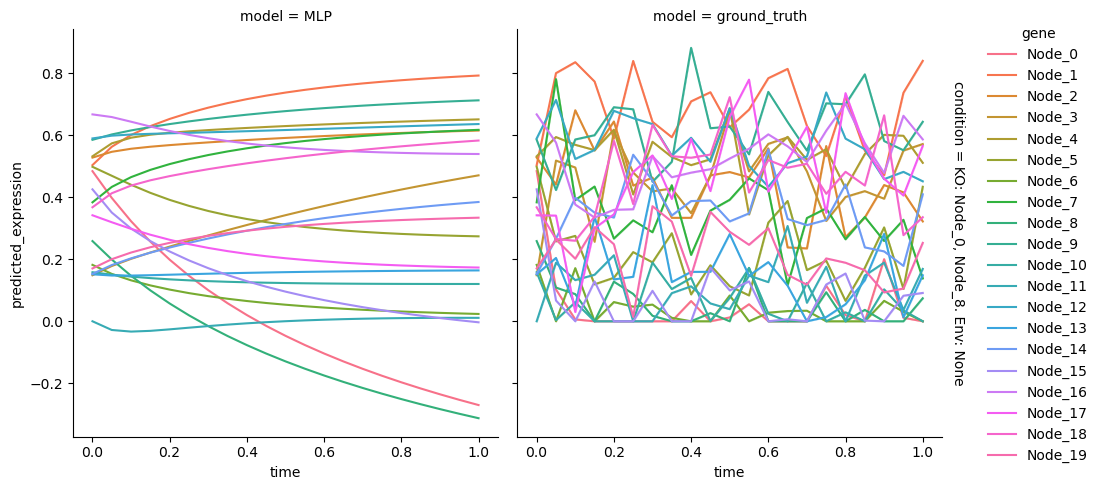

In [58]:
# Add ground truth as kind of model
df_with_gt_as_model = df_with_ground_truth_as_kind_of_model(df)
# Filter for only one KO
filtered_df = df_with_gt_as_model[df_with_gt_as_model['condition'] == "KO: Node_0, Node_8. Env: None"]
plot_model_plots(filtered_df)

## Alternative visualisation

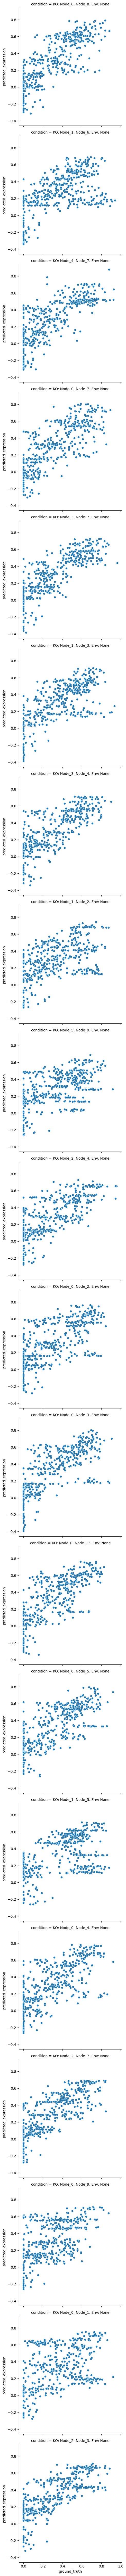

In [57]:
sns.relplot(data=df, x='ground_truth', y='predicted_expression', row='condition', kind='scatter')